# Домашнее задание 1: персональные top-10 рекомендации

**Гришанова Арина Вадимовна**  
**Датасет:** [Amazon Reviews 2023, Software](https://amazon-reviews-2023.github.io/).

**Запуск из корня репозитория:**

```powershell
python -m pip install -r requirements.txt
python -m notebook experiments.ipynb
```

Запустите ячейки по порядку. Первая скачает отзывы и метаданные в `data/`.
Для воспроизводимости задано случайное зерно `SEED = 42`.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from hashlib import sha256
from time import perf_counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display

from models import ItemKNN, ImplicitALS, EASE, FactorizationMachine, RatingTargetIALS

SEED = 42
np.random.seed(SEED)
DATA = Path('data')
DATA.mkdir(exist_ok=True)
SOURCE = 'https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/'
FILES = {
    'Software.csv': (
        'benchmark/5core/rating_only/Software.csv',
        '6538476c9cb20fc983a829d06be796b1929be4f10171b1d551899caf5b3e0590',
    ),
    'meta_Software.jsonl': (
        'raw/meta_categories/meta_Software.jsonl',
        '7c52cce1bf3bff33f965fe117e3e8fac18a1839f88b215efa50b31a8230a5f58',
    ),
}
for name, (relative_url, expected_hash) in FILES.items():
    path = DATA / name
    if not path.exists():
        print('Скачивание:', name)
        urlretrieve(SOURCE + relative_url, path)
    digest = sha256(path.read_bytes()).hexdigest()
    assert digest == expected_hash, f'Не совпала контрольная сумма: {name}'
print('Исходные файлы готовы; контрольные суммы совпадают.')

Исходные файлы готовы; контрольные суммы совпадают.


## 1. Данные

Используем оценки товаров категории Software: `user_id`, `parent_asin`, `rating`, `timestamp`.
Из метаданных берём `title`, `store` и `main_category`.
По событиям до 01.04.2016 выбираем 1500 товаров и 8000 пользователей с не менее чем
8 отзывами; более поздние события оставляем для проверки. В итоговой выборке —
126 617 взаимодействий. Ссылки на исходные файлы указаны в ячейке загрузки.

In [2]:
TRAIN_END = pd.Timestamp('2016-04-01', tz='UTC').value // 10**6
VALID_END = pd.Timestamp('2017-01-01', tz='UTC').value // 10**6
N_PRODUCTS = 1500
MIN_TRAIN_EVENTS = 8
MAX_USERS = 8000

raw = pd.read_csv(DATA / 'Software.csv')
raw_count = len(raw)
missing = raw.isna().sum()
raw = raw.dropna(subset=['user_id', 'parent_asin', 'rating', 'timestamp'])
raw = raw[raw['rating'].between(1, 5)].copy()
raw = raw.sort_values(['timestamp', 'user_id', 'parent_asin'])
duplicates = int(raw.duplicated(['user_id', 'parent_asin']).sum())
raw = raw.drop_duplicates(['user_id', 'parent_asin'], keep='first')

early = raw[raw.timestamp < TRAIN_END]
item_counts = early.groupby('parent_asin').size().reset_index(name='events')
item_counts = item_counts.sort_values(['events', 'parent_asin'], ascending=[False, True])
item_ids = sorted(item_counts.head(N_PRODUCTS).parent_asin)
selected = raw[raw.parent_asin.isin(item_ids)].copy()
user_counts = selected.loc[selected.timestamp < TRAIN_END].groupby('user_id').size()
eligible_users = user_counts[user_counts >= MIN_TRAIN_EVENTS]
user_ids = sorted(eligible_users.sort_values(ascending=False, kind='stable').head(MAX_USERS).index)
selected = selected[selected.user_id.isin(user_ids)].copy()
user_map = {key: index for index, key in enumerate(user_ids)}
item_map = {key: index for index, key in enumerate(item_ids)}
selected['user'] = selected.user_id.map(user_map).astype('int32')
selected['item'] = selected.parent_asin.map(item_map).astype('int32')
N_USERS, N_ITEMS = len(user_ids), len(item_ids)

summary = pd.DataFrame({
    'stage': ['исходный файл', 'после очистки', 'итоговая выборка'],
    'interactions': [raw_count, len(raw), len(selected)],
    'users': [pd.read_csv(DATA / 'Software.csv', usecols=['user_id']).user_id.nunique(),
              raw.user_id.nunique(), N_USERS],
    'items': [pd.read_csv(DATA / 'Software.csv', usecols=['parent_asin']).parent_asin.nunique(),
              raw.parent_asin.nunique(), N_ITEMS],
})
display(summary.rename(columns={'stage': 'Этап', 'interactions': 'Взаимодействия', 'users': 'Пользователи', 'items': 'Товары'}))
print('Пропуски:', missing.to_dict(), '| дубликаты пар пользователь–товар:', duplicates)
assert 100_000 <= len(selected) <= 2_000_000
assert N_USERS >= 1000 and N_ITEMS >= 1000

Пропуски: {'user_id': 0, 'parent_asin': 0, 'rating': 0, 'timestamp': 0} | дубликаты пар пользователь–товар: 0


,Этап,Взаимодействия,Пользователи,Товары
0,исходный файл,1276840,146396,17591
1,после очистки,1276840,146396,17591
2,итоговая выборка,126617,8000,1500


In [3]:
selected_ids = set(item_ids)
metadata_rows = {}
with (DATA / 'meta_Software.jsonl').open(encoding='utf-8') as stream:
    for line in stream:
        row = json.loads(line)
        asin = row.get('parent_asin')
        if asin in selected_ids:
            metadata_rows[asin] = {
                'item': item_map[asin],
                'title': row.get('title') or '',
                'store': row.get('store') or '',
                'main_category': row.get('main_category') or '',
            }
metadata = pd.DataFrame(metadata_rows.values()).sort_values('item').reset_index(drop=True)
assert len(metadata) == N_ITEMS
print('Заполненность метаданных:')
display((metadata[['title', 'store', 'main_category']] != '').mean().rename('Доля заполненных'))
display(metadata[['item', 'title', 'store', 'main_category']].head())

Заполненность метаданных:


,Доля заполненных
title,1.0
store,1.0
main_category,1.0


,item,title,store,main_category
0,0,Microsoft Office Home and Student 2007 Old Version,Microsoft,Software
1,1,"OLD VERSION Microsoft Office Home and Student 2010 Family Pack, 3PC (Disc Version)",Microsoft,Software
2,2,Daily Bible,JoanSoft,Appstore for Android
3,3,TV Listings by TV24 - TV Guide,Jersey Productions,Appstore for Android
4,4,Kindle for Android,Amazon.com,Appstore for Android


## 2. Анализ и разбиение

Проверяем пропуски, дубликаты, активность пользователей, популярность товаров,
распределение оценок, плотность матрицы и заполненность метаданных.
Обучение — до 01.04.2016, валидация — с 01.04.2016 до 01.01.2017,
тест — с 01.01.2017.

Плотность матрицы: 0.009708916666666666


,Часть,Взаимодействия,Пользователи,Товары,Оценки 4–5
0,обучение,116507,8000,1500,84475
1,валидация,4305,1966,794,3078
2,тест,5805,2196,795,4156


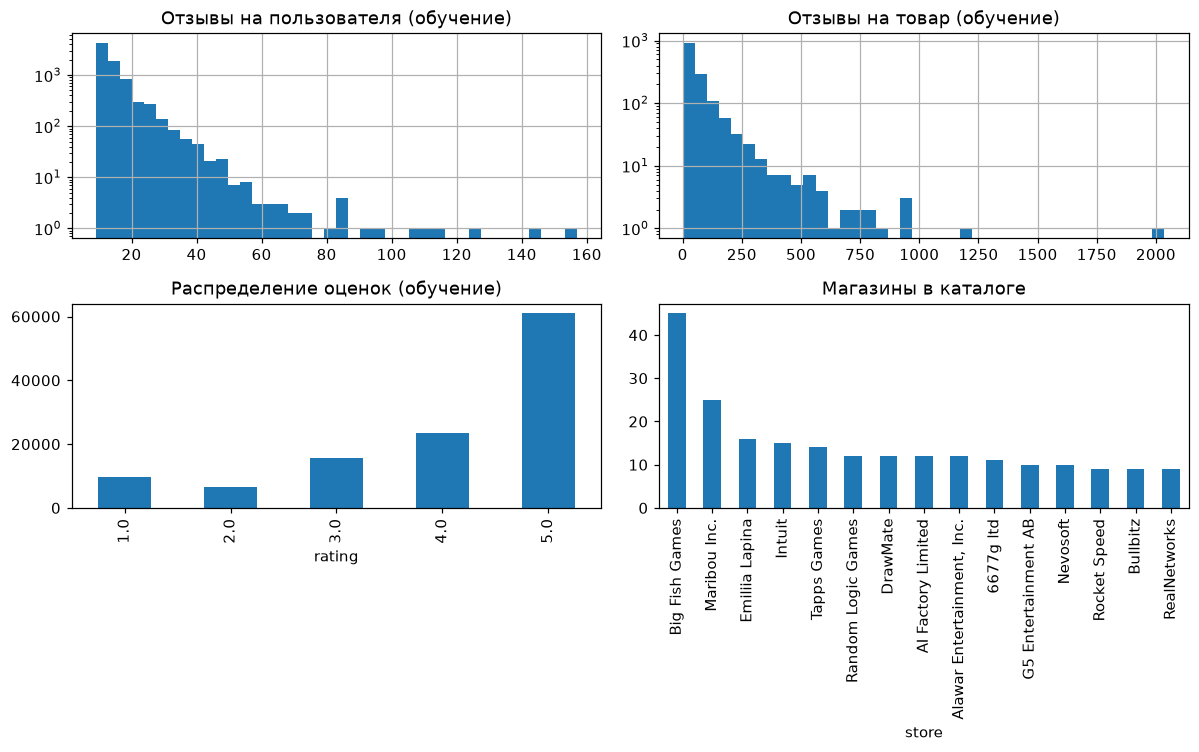

In [4]:
train = selected[selected.timestamp < TRAIN_END].copy()
valid = selected[(selected.timestamp >= TRAIN_END) & (selected.timestamp < VALID_END)].copy()
test = selected[selected.timestamp >= VALID_END].copy()
train_valid = pd.concat([train, valid], ignore_index=True)
split_summary = pd.DataFrame({
    'split': ['обучение', 'валидация', 'тест'],
    'rows': [len(train), len(valid), len(test)],
    'users': [train.user.nunique(), valid.user.nunique(), test.user.nunique()],
    'items': [train.item.nunique(), valid.item.nunique(), test.item.nunique()],
    'relevant_rows_rating_4_5': [int((part.rating >= 4).sum()) for part in [train, valid, test]],
})
display(split_summary.rename(columns={'split': 'Часть', 'rows': 'Взаимодействия', 'users': 'Пользователи', 'items': 'Товары', 'relevant_rows_rating_4_5': 'Оценки 4–5'}))
print('Плотность матрицы:', len(train) / (N_USERS * N_ITEMS))
assert set(valid.user).issubset(set(train.user))
assert set(test.user).issubset(set(train.user))
assert set(valid.item).issubset(set(train.item))
assert set(test.item).issubset(set(train.item))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
train.groupby('user').size().hist(ax=axes[0, 0], bins=40, log=True)
axes[0, 0].set_title('Отзывы на пользователя (обучение)')
train.groupby('item').size().hist(ax=axes[0, 1], bins=40, log=True)
axes[0, 1].set_title('Отзывы на товар (обучение)')
train.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0])
axes[1, 0].set_title('Распределение оценок (обучение)')
metadata.store.value_counts().head(15).plot.bar(ax=axes[1, 1])
axes[1, 1].set_title('Магазины в каталоге')
fig.tight_layout()
plt.show()

## 3. Оценка top-10

Релевантным считаем товар с отложенной оценкой 4–5. Кандидаты для всех моделей —
1500 товаров из обучения; уже известные пользователю товары исключаем.
Параметры выбираем по NDCG@10 на валидации. Дополнительно считаем Recall@10
и coverage@10. Метрики усредняем по пользователям, у которых есть хотя бы
один релевантный товар в отложенной части.

In [5]:
def history_matrix(frame):
    matrix = sparse.csr_matrix(
        (np.ones(len(frame), dtype=np.float32), (frame.user, frame.item)),
        shape=(N_USERS, N_ITEMS),
    )
    matrix.data[:] = 1
    return matrix


train_history = history_matrix(train)
train_valid_history = history_matrix(train_valid)


def evaluate(model, holdout, known):
    relevant = holdout.loc[holdout.rating >= 4].groupby('user').item.agg(list)
    users = relevant.index.to_numpy(dtype=np.int32)
    if len(users) == 0:
        raise ValueError('Нет пользователей с релевантными товарами в этой части данных')
    top = model.recommend(users, k=10, exclude=known)
    assert top.shape == (len(users), 10)
    recalls, ndcgs = [], []
    for row, truth in enumerate(relevant):
        truth = set(truth)
        hits = np.array([item in truth for item in top[row]], dtype=np.float64)
        recalls.append(hits.sum() / len(truth))
        discounts = 1 / np.log2(np.arange(2, 12))
        ideal = discounts[:min(len(truth), 10)].sum()
        ndcgs.append((hits * discounts).sum() / ideal)
    return {
        'Recall@10': float(np.mean(recalls)),
        'NDCG@10': float(np.mean(ndcgs)),
        'coverage@10': len(np.unique(top)) / N_ITEMS,
        'evaluated_users': len(users),
    }


print('Пользователей в валидации:', valid.loc[valid.rating >= 4, 'user'].nunique())
print('Пользователей в тесте:', test.loc[test.rating >= 4, 'user'].nunique())

Пользователей в валидации: 1654
Пользователей в тесте: 1831


## 4. Модели

1. **ItemKNN** — рекомендует товары, похожие на уже известные пользователю.
2. **iALS** — раскладывает матрицу взаимодействий на признаки пользователей и товаров.
3. **EASE** — строит линейные связи между товарами.
4. **FM** — использует ID, слова из названия, магазин и категорию. Для обучения
   добавляем по одному неизвестному товару на каждый положительный отзыв как
   приближённый отрицательный пример.
5. **RatingTargetIALS** — та же функция потерь и уверенность, что у iALS, но
   другая цель для известных оценок: `p_ui = clip((rating_ui - 3) / 2, 0, 1)`.
   Оценка 4 даёт цель 0,5, оценка 5 — 1. Проверяем, поможет ли учёт силы оценки.

In [6]:
GRID = {
    'ItemKNN': [
        {'neighbors': 50, 'shrinkage': 10.0},
        {'neighbors': 150, 'shrinkage': 20.0},
    ],
    'iALS': [
        {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
        {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
    ],
    'EASE': [
        {'regularization': 100.0},
        {'regularization': 500.0},
    ],
    'FM': [
        {'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001,
         'epochs': 4, 'batch_size': 4096, 'seed': SEED},
        {'factors': 16, 'learning_rate': 0.02, 'regularization': 0.001,
         'epochs': 4, 'batch_size': 4096, 'seed': SEED},
    ],
    'RatingTargetIALS': [
        {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
        {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': SEED},
    ],
}


def make_model(name, params, use_metadata=True):
    cls = {'ItemKNN': ItemKNN, 'iALS': ImplicitALS, 'EASE': EASE,
           'FM': FactorizationMachine, 'RatingTargetIALS': RatingTargetIALS}[name]
    if name == 'FM':
        return cls(**params, use_metadata=use_metadata)
    return cls(**params)


def fit_model(model, data):
    if isinstance(model, FactorizationMachine):
        return model.fit(data, N_USERS, N_ITEMS, metadata)
    return model.fit(data, N_USERS, N_ITEMS)


validation_rows = []
for name, configurations in GRID.items():
    for params in configurations:
        start = perf_counter()
        model = fit_model(make_model(name, params), train)
        metrics = evaluate(model, valid, train_history)
        validation_rows.append({'model': name, 'params': params,
                                'fit_seconds': round(perf_counter() - start, 1), **metrics})
        print(name, params, 'NDCG@10 на валидации =', round(metrics['NDCG@10'], 4))
validation_results = pd.DataFrame(validation_rows)
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]).rename(columns={'model': 'Модель', 'params': 'Параметры', 'fit_seconds': 'Обучение, с', 'coverage@10': 'Охват@10', 'evaluated_users': 'Пользователи'}))
chosen = (validation_results.sort_values(['NDCG@10', 'Recall@10'], ascending=False)
          .drop_duplicates('model').set_index('model'))
print('Выбранные параметры по валидации:')
display(chosen[['params', 'Recall@10', 'NDCG@10']].rename_axis('Модель').rename(columns={'params': 'Параметры'}))

ItemKNN {'neighbors': 50, 'shrinkage': 10.0} NDCG@10 на валидации = 0.0724
ItemKNN {'neighbors': 150, 'shrinkage': 20.0} NDCG@10 на валидации = 0.0725
iALS {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 на валидации = 0.0575
iALS {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 на валидации = 0.0528
EASE {'regularization': 100.0} NDCG@10 на валидации = 0.0765
EASE {'regularization': 500.0} NDCG@10 на валидации = 0.0717
FM {'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42} NDCG@10 на валидации = 0.0311
FM {'factors': 16, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42} NDCG@10 на валидации = 0.0271
RatingTargetIALS {'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42} NDCG@10 на валидации = 0.0512
RatingTargetIALS {'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterat

,Модель,Параметры,"Обучение, с",Recall@10,NDCG@10,Охват@10,Пользователи
4,EASE,{'regularization': 100.0},0.4,0.130422,0.076511,0.406667,1654
5,EASE,{'regularization': 500.0},0.4,0.120969,0.071713,0.280000,1654
6,FM,"{'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}",0.8,0.055725,0.031090,0.013333,1654
7,FM,"{'factors': 16, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}",1.9,0.052187,0.027068,0.013333,1654
1,ItemKNN,"{'neighbors': 150, 'shrinkage': 20.0}",0.2,0.116788,0.072476,0.413333,1654
0,ItemKNN,"{'neighbors': 50, 'shrinkage': 10.0}",0.2,0.117189,0.072446,0.529333,1654
8,RatingTargetIALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.2,0.091649,0.051189,0.210667,1654
9,RatingTargetIALS,"{'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.2,0.079816,0.043731,0.266000,1654
2,iALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.2,0.098082,0.057508,0.228000,1654
3,iALS,"{'factors': 16, 'alpha': 30.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",1.3,0.091673,0.052762,0.310000,1654


,Параметры,Recall@10,NDCG@10
Модель,,,
EASE,{'regularization': 100.0},0.130422,0.076511
ItemKNN,"{'neighbors': 150, 'shrinkage': 20.0}",0.116788,0.072476
iALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",0.098082,0.057508
RatingTargetIALS,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}",0.091649,0.051189
FM,"{'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}",0.055725,0.031090


### Вклад метаданных в FM

На валидации сравниваем FM с признаками товара и FM только с ID.

In [7]:
fm_params = chosen.loc['FM', 'params']
fm_ids = fit_model(make_model('FM', fm_params, use_metadata=False), train)
fm_ids_valid = evaluate(fm_ids, valid, train_history)
display(pd.DataFrame([
    {'variant': 'FM с метаданными', **validation_results.loc[
        (validation_results.model == 'FM') &
        (validation_results.params.map(str) == str(fm_params))
    ].iloc[0][['Recall@10', 'NDCG@10', 'coverage@10', 'evaluated_users']].to_dict()},
    {'variant': 'FM только с ID', **fm_ids_valid},
]).set_index('variant').rename_axis('Вариант').rename(columns={'coverage@10': 'Охват@10', 'evaluated_users': 'Пользователи'}))

,Recall@10,NDCG@10,Охват@10,Пользователи
Вариант,,,,
FM с метаданными,0.055725,0.031090,0.013333,1654
FM только с ID,0.047078,0.029921,0.016000,1654


## 5. Сравнение на тесте

Для каждой модели берём параметры, выбранные на валидации, переобучаем её
на обучении вместе с валидацией и один раз оцениваем на тесте.

ItemKNN NDCG@10 на тесте = 0.0578
iALS NDCG@10 на тесте = 0.0547
EASE NDCG@10 на тесте = 0.0635
FM NDCG@10 на тесте = 0.0382
RatingTargetIALS NDCG@10 на тесте = 0.0504


,Модель,Recall@10,NDCG@10,Охват@10,Пользователи,"Обучение, с",Параметры
2,EASE,0.108277,0.063501,0.412000,1831,0.5,{'regularization': 100.0}
0,ItemKNN,0.098185,0.057835,0.421333,1831,0.3,"{'neighbors': 150, 'shrinkage': 20.0}"
1,iALS,0.089188,0.054709,0.239333,1831,1.2,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}"
4,RatingTargetIALS,0.081817,0.050439,0.215333,1831,1.2,"{'factors': 16, 'alpha': 10.0, 'regularization': 0.1, 'iterations': 3, 'seed': 42}"
3,FM,0.064220,0.038244,0.012667,1831,0.8,"{'factors': 8, 'learning_rate': 0.02, 'regularization': 0.001, 'epochs': 4, 'batch_size': 4096, 'seed': 42}"


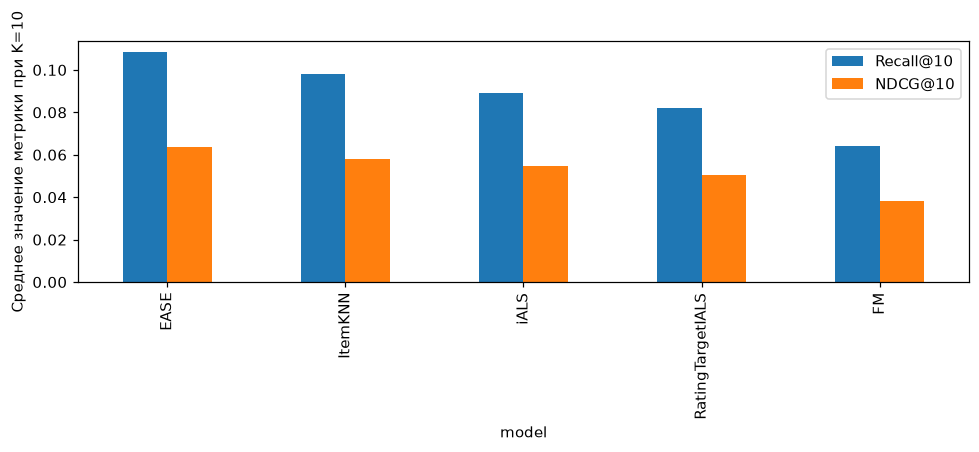

In [8]:
final_models = {}
test_rows = []
for name in GRID:
    params = chosen.loc[name, 'params']
    start = perf_counter()
    model = fit_model(make_model(name, params), train_valid)
    final_models[name] = model
    metrics = evaluate(model, test, train_valid_history)
    test_rows.append({'model': name, 'params': params,
                      'fit_seconds': round(perf_counter() - start, 1), **metrics})
    print(name, 'NDCG@10 на тесте =', round(metrics['NDCG@10'], 4))
test_results = pd.DataFrame(test_rows).sort_values('NDCG@10', ascending=False)
display(test_results[['model', 'Recall@10', 'NDCG@10', 'coverage@10',
                      'evaluated_users', 'fit_seconds', 'params']].rename(columns={'model': 'Модель', 'params': 'Параметры', 'fit_seconds': 'Обучение, с', 'coverage@10': 'Охват@10', 'evaluated_users': 'Пользователи'}))
ax = test_results.set_index('model')[['Recall@10', 'NDCG@10']].plot.bar(figsize=(9, 4))
ax.set_ylabel('Среднее значение метрики при K=10')
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

## 6. Ограничения

Оцениваем только пользователей и товары, известные до валидации.
Отсутствие взаимодействия не означает отрицательную оценку.
Метаданные взяты из более позднего снимка каталога, поэтому их историческую
доступность нельзя подтвердить. Исходный набор `5-core` уже был отфильтрован авторами.

In [9]:
best = test_results.iloc[0]
base = test_results.set_index('model').loc['iALS']
custom = test_results.set_index('model').loc['RatingTargetIALS']
meta_ndcg = float(chosen.loc['FM', 'NDCG@10'])
print(f"Лучшая модель на тесте по NDCG@10: {best['model']} ({best['NDCG@10']:.4f}); "
      f"Recall@10 = {best['Recall@10']:.4f}.")
print(f"Изменённая цель против обычного iALS на тесте: "
      f"разница NDCG@10 = {custom['NDCG@10'] - base['NDCG@10']:+.4f}, "
      f"разница Recall@10 = {custom['Recall@10'] - base['Recall@10']:+.4f}.")
print(f"FM с метаданными против FM только с ID на валидации: "
      f"разница NDCG@10 = {meta_ndcg - fm_ids_valid['NDCG@10']:+.4f}.")

Лучшая модель на тесте по NDCG@10: EASE (0.0635); Recall@10 = 0.1083.
Изменённая цель против обычного iALS на тесте: разница NDCG@10 = -0.0043, разница Recall@10 = -0.0074.
FM с метаданными против FM только с ID на валидации: разница NDCG@10 = +0.0012.


## Вывод

Лучший результат дал EASE: NDCG@10 = 0,0635 и Recall@10 = 0,1083.
Изменённая цель ALS здесь уступила обычному iALS. Метаданные немного улучшили
FM на валидации, но её рекомендации охватывают мало товаров.